# 22. Majorization and Doubly Stochastic Matrices
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

Lorenz curves (partial sums of the entries in increasing order, normalized by the total). The uniform vector gives the diagonal; more spread-out vectors sag lower. Here $x\prec y\prec z$, so their curves are nested. A vector incomparable with $y$ would have a curve crossing $y$'s.

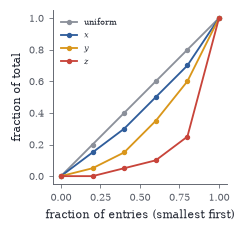

In [2]:
x = np.array([3, 3, 4, 4, 6.]); y = np.array([1, 2, 4, 5, 8.]); z = np.array([0, 1, 1, 3, 15.])
fig, ax = plt.subplots(figsize=(W * 0.55, 2.0))
for v, col, lab in [(np.full(5, 4.0), GRAY, "uniform"), (x, BLUE, "$x$"), (y, GOLD, "$y$"), (z, RED, "$z$")]:
    L = np.r_[0, np.cumsum(np.sort(v))] / v.sum(); ax.plot(np.arange(6) / 5, L, "o-", color=col, ms=2.5, label=lab)
ax.set_xlabel("fraction of entries (smallest first)"); ax.set_ylabel("fraction of total"); ax.legend(fontsize=5.5); ax.set_aspect("equal")

The permutohedron of $y=(3,1,0)$: the convex hull of its six rearrangements, a hexagon in the plane $x_1+x_2+x_3=4$, viewed face-on. The points $Ay$ for $3000$ random doubly stochastic matrices $A$ (blue) fill exactly this hexagon, which is the set $\{x:x\prec y\}$; the uniform vector $(\frac43,\frac43,\frac43)$ sits at the centre.

(np.float64(-2.3334523779156067),
 np.float64(2.3334523779156067),
 np.float64(-2.2249531830280533),
 np.float64(1.8167048925641907))

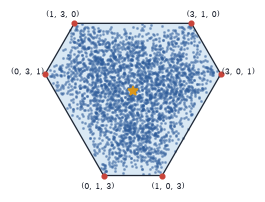

In [3]:
from itertools import permutations
y = np.array([3.0, 1.0, 0.0]); P = np.array(sorted(set(permutations(y))))
e1 = np.array([1, -1, 0]) / np.sqrt(2); e2 = np.array([1, 1, -2]) / np.sqrt(6)
proj = lambda v: np.c_[v @ e1, v @ e2]
rng = np.random.default_rng(0); pts = []
for _ in range(3000):
    w = rng.dirichlet(np.ones(6) * 0.4); M = sum(wi * np.eye(3)[list(p)] for wi, p in zip(w, permutations(range(3))))
    pts.append(M @ y)
pts = np.array(pts); hull = proj(P); ang = np.arctan2(hull[:, 1], hull[:, 0]); hull = hull[np.argsort(ang)]
fig, ax = plt.subplots(figsize=(W * 0.5, W * 0.45))
ax.scatter(*proj(pts).T, s=1, color=BLUE, alpha=0.4); ax.fill(*hull.T, color=SKY, alpha=0.25, zorder=0); ax.plot(*np.r_[hull, hull[:1]].T, color=INK, lw=0.8)
for p in P:
    q = proj(p[None])[0]; ax.plot(*q, "o", color=RED, ms=3); ax.text(q[0] * 1.2, q[1] * 1.13 - 0.06, f"{tuple(int(v) for v in p)}", fontsize=5.5, ha="center")
ax.plot(0, 0, "*", color=GOLD, ms=7); ax.set_aspect("equal"); ax.axis("off")

In [4]:
rng = np.random.default_rng(1); n = 4
from scipy.optimize import linear_sum_assignment
w = rng.dirichlet(np.ones(5)); perms = [rng.permutation(n) for _ in range(5)]
A = sum(wi * np.eye(n)[p] for wi, p in zip(w, perms)); terms = []; B = A.copy()
while B.max() > 1e-12:                                          # Birkhoff decomposition, greedy
    r, c = linear_sum_assignment(-np.log(np.maximum(B, 1e-300)))   # a positive diagonal (max product)
    lam = B[r, c].min(); terms.append((lam, c)); B[r, c] -= lam
print("number of permutation matrices used:", len(terms), "  weights sum to:", round(sum(t[0] for t in terms), 12))
print("reconstruction exact:", np.allclose(sum(l * np.eye(n)[c] for l, c in terms), A))

number of permutation matrices used: 3   weights sum to: 1.0
reconstruction exact: True


Sinkhorn scaling of $A=e^{C/\varepsilon}$ for a random $6\times6$ score matrix $C$. Left: the deviation of row and column sums from $1$ falls geometrically with the number of iterations. Right: the resulting doubly stochastic matrices for decreasing $\varepsilon$ sharpen towards the permutation matrix that solves the assignment problem $\max_\sigma\sum c_{i\sigma(i)}$ (outlined).

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


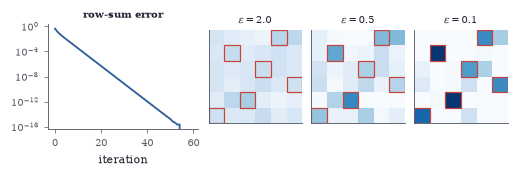

In [5]:
rng = np.random.default_rng(2); C = rng.normal(size=(6, 6)); r, cbest = linear_sum_assignment(-C)
def sinkhorn(Kmat, iters):
    M = Kmat.copy(); dev = []
    for _ in range(iters):
        M /= M.sum(1, keepdims=True); M /= M.sum(0, keepdims=True); dev.append(np.abs(M.sum(1) - 1).max())
    return M, dev
fig, axs = plt.subplots(1, 4, figsize=(W, 1.5), gridspec_kw={"width_ratios": [1.6, 1, 1, 1]})
_, dev = sinkhorn(np.exp(C / 0.5), 60); axs[0].semilogy(dev, color=BLUE); axs[0].set_xlabel("iteration"); axs[0].set_title("row-sum error", fontsize=6.5)
for ax, eps in zip(axs[1:], [2.0, 0.5, 0.1]):
    M, _ = sinkhorn(np.exp((C - C.max()) / eps), 500); ax.imshow(M, cmap="Blues", vmin=0, vmax=1)
    for i, j in zip(r, cbest): ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec=RED, lw=0.8))
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(rf"$\varepsilon={eps}$", fontsize=6.5)

The Schur–Horn theorem in three dimensions. For a fixed spectrum $\lambda=(3,1,0)$, the diagonals of $3000$ random real symmetric matrices $Q\,\mathrm{diag}(\lambda)\,Q^{\mathsf T}$ with $Q$ uniformly random orthogonal (blue) fill the permutohedron of $\lambda$ (the hexagon), as Schur's and Horn's theorems predict, though not uniformly.

(np.float64(-2.3334523779156067),
 np.float64(2.3334523779156067),
 np.float64(-2.2249531830280533),
 np.float64(1.8167048925641907))

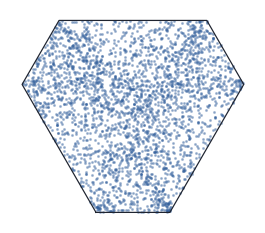

In [6]:
lam = np.array([3.0, 1.0, 0.0]); rng = np.random.default_rng(3); D = []
for _ in range(3000):
    Q, R = np.linalg.qr(rng.normal(size=(3, 3))); Q = Q * np.sign(np.diag(R)); D.append(np.diag(Q @ np.diag(lam) @ Q.T))
D = np.array(D); P = np.array(sorted(set(permutations(lam)))); hull = proj(P); hull = hull[np.argsort(np.arctan2(hull[:, 1], hull[:, 0]))]
fig, ax = plt.subplots(figsize=(W * 0.5, W * 0.45))
ax.scatter(*proj(D).T, s=1, color=BLUE, alpha=0.35); ax.plot(*np.r_[hull, hull[:1]].T, color=INK, lw=0.8); ax.set_aspect("equal"); ax.axis("off")

In [7]:
from scipy.optimize import linprog
rng = np.random.default_rng(5); n = 8; C = rng.normal(size=(n, n))
Aeq = np.zeros((2 * n, n * n))
for i in range(n): Aeq[i, i * n:(i + 1) * n] = 1; Aeq[n + i, i::n] = 1
res = linprog(-C.ravel(), A_eq=Aeq, b_eq=np.ones(2 * n), bounds=(0, None), method="highs")
X = res.x.reshape(n, n); r, c = linear_sum_assignment(-C)
print("LP value:", round(-res.fun, 6), "  Hungarian value:", round(C[r, c].sum(), 6))
print("LP solution is a permutation matrix:", np.allclose(X, np.eye(n)[np.argmax(X, 1)]))

LP value: 7.194153   Hungarian value: 7.194153
LP solution is a permutation matrix: True


In [8]:
rng = np.random.default_rng(6); A = rng.normal(size=(6, 6)); Cp = A.copy(); Cp[:3, 3:] = 0; Cp[3:, :3] = 0
for nm, o in [("nuclear", "nuc"), ("operator", 2), ("Frobenius", "fro")]:
    print(f"{nm:9s}  ||C(A)|| = {np.linalg.norm(Cp, o):.4f}  <=  ||A|| = {np.linalg.norm(A, o):.4f}")

nuclear    ||C(A)|| = 9.0198  <=  ||A|| = 13.0446
operator   ||C(A)|| = 3.4187  <=  ||A|| = 4.4146
Frobenius  ||C(A)|| = 4.3960  <=  ||A|| = 6.2901


In [9]:
gini = lambda v: np.abs(v[:, None] - v[None, :]).sum() / (2 * len(v) * v.sum())
for name, v in [("x", np.array([3, 3, 4, 4, 6.])), ("y", np.array([1, 2, 4, 5, 8.])), ("z", np.array([0, 1, 1, 3, 15.]))]:
    print(name, round(gini(v), 4))

x 0.14
y 0.34
z 0.64
